# Mini-Task 8 — Part 1: Spoken "Yes" / "No" Classification

**Course:** Digital Speech Processing — Dr. Khalooei  
**Student:** Ghassan Alsafar — **ID:** 404131085

Run the cells from top to bottom (**Kernel → Restart & Run All**). The full pipeline lives in `yesno_classification.py`; this notebook runs it and shows the results.

## 1. Install the libraries (only needed once)

In [17]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


## 2. Run the whole experiment
Downloads the dataset, segments the words, extracts MFCC features, trains 6 classifiers, runs the noise test and writes `README.md`, `figures/` and `results/`.

In [23]:
%run yesno_classification.py

[1/7] Dataset
  60 recordings, sample rate 8000 Hz
[2/7] Word segmentation
  exactly 8 words in 59/60 recordings -> 472 words
[3/7] Features + exploration figures
  saved figures/fig01_signal_and_spectrogram.png
  saved figures/fig02_energy_segmentation.png
  saved figures/fig03_yes_vs_no.png
  saved figures/fig04_feature_space_pca.png
[4/7] Classifier comparison (grouped 5-fold CV)
  SVM (RBF)               98.31% ± 1.41
  Neural Network (MLP)    98.54% ± 1.93
  KNN (k=5)               98.12% ± 1.67
  Random Forest           98.54% ± 1.56
  Logistic Regression     98.31% ± 1.81
  Naive Bayes             98.54% ± 1.56
  saved figures/fig05_model_comparison.png
[5/7] Noise robustness
  SNR  clean: SVM 98%, Neural 99%, KNN 97%, Random 98%, Logistic 99%, Naive 98%
  SNR  20 dB: SVM 89%, Neural 75%, KNN 95%, Random 98%, Logistic 78%, Naive 98%
  SNR  15 dB: SVM 75%, Neural 63%, KNN 92%, Random 97%, Logistic 72%, Naive 98%
  SNR  10 dB: SVM 52%, Neural 55%, KNN 83%, Random 90%, Logistic 72%

## 3. Figures

**fig01_signal_and_spectrogram**

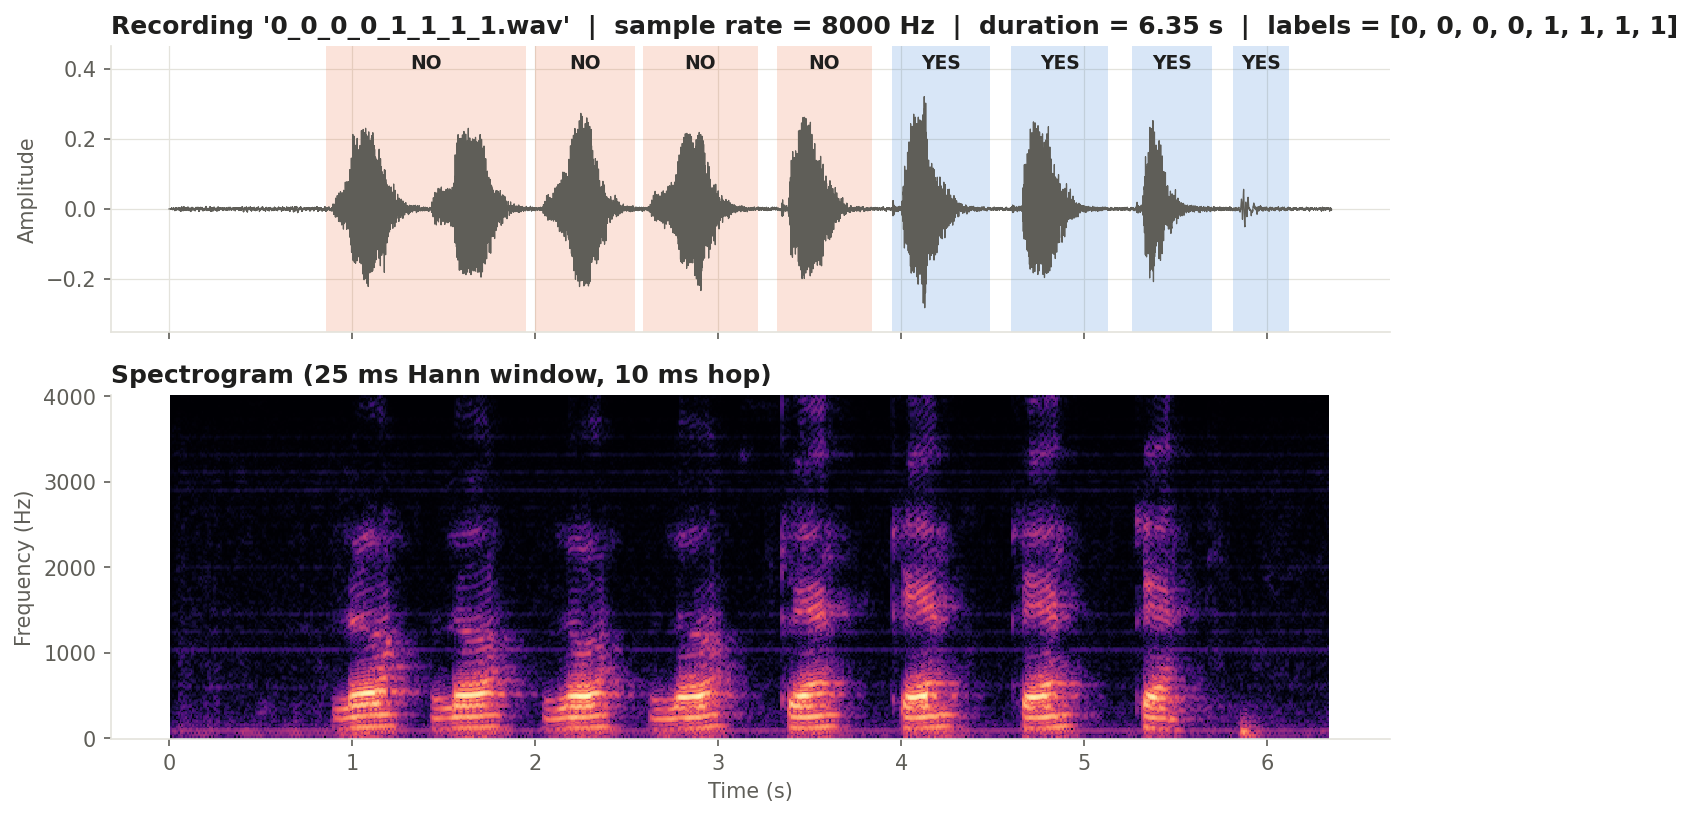

**fig02_energy_segmentation**

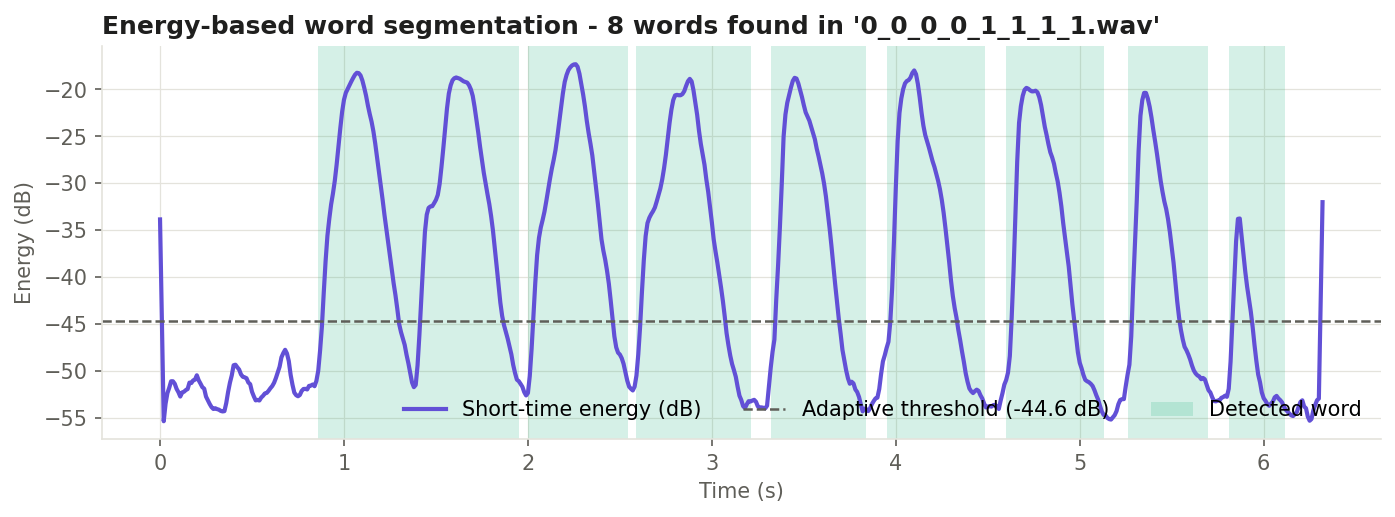

**fig03_yes_vs_no**

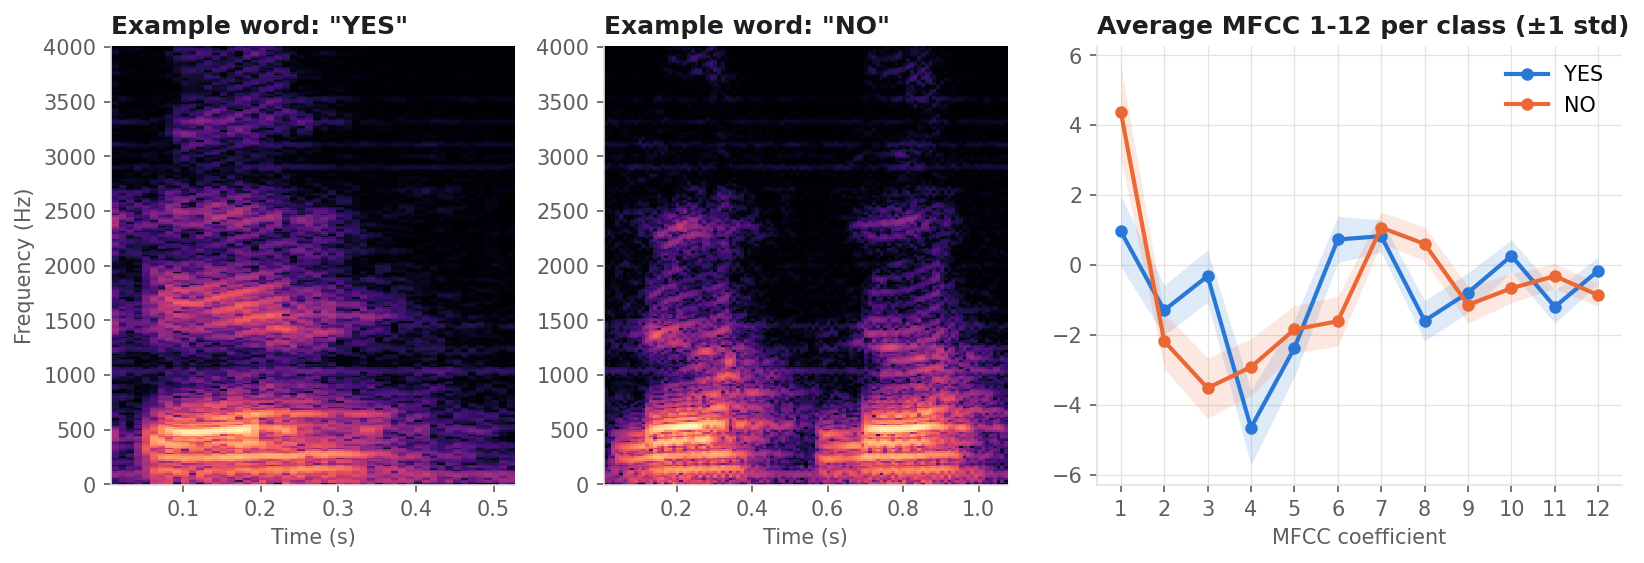

**fig04_feature_space_pca**

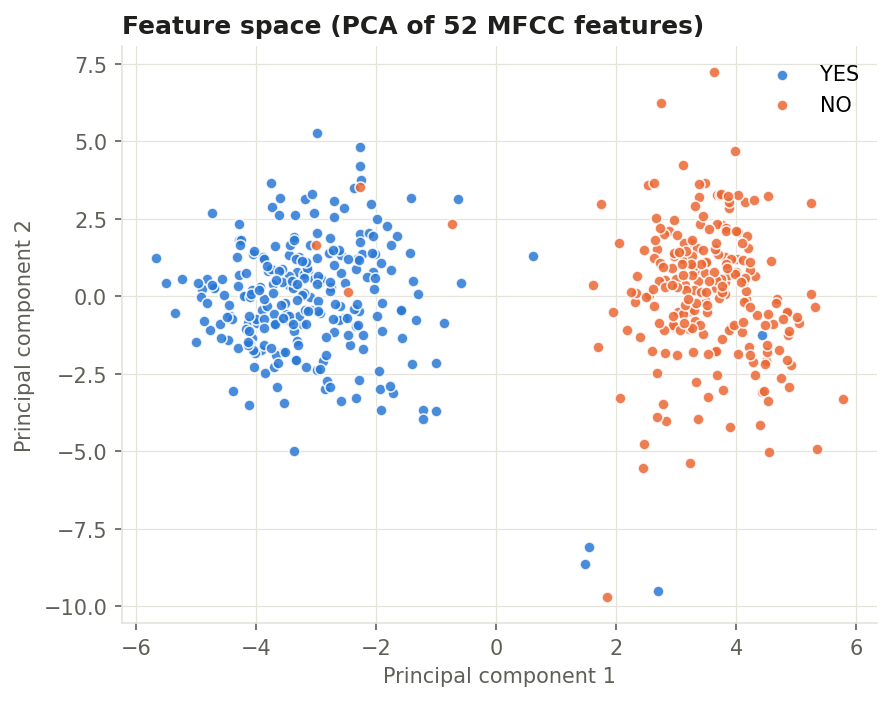

**fig05_model_comparison**

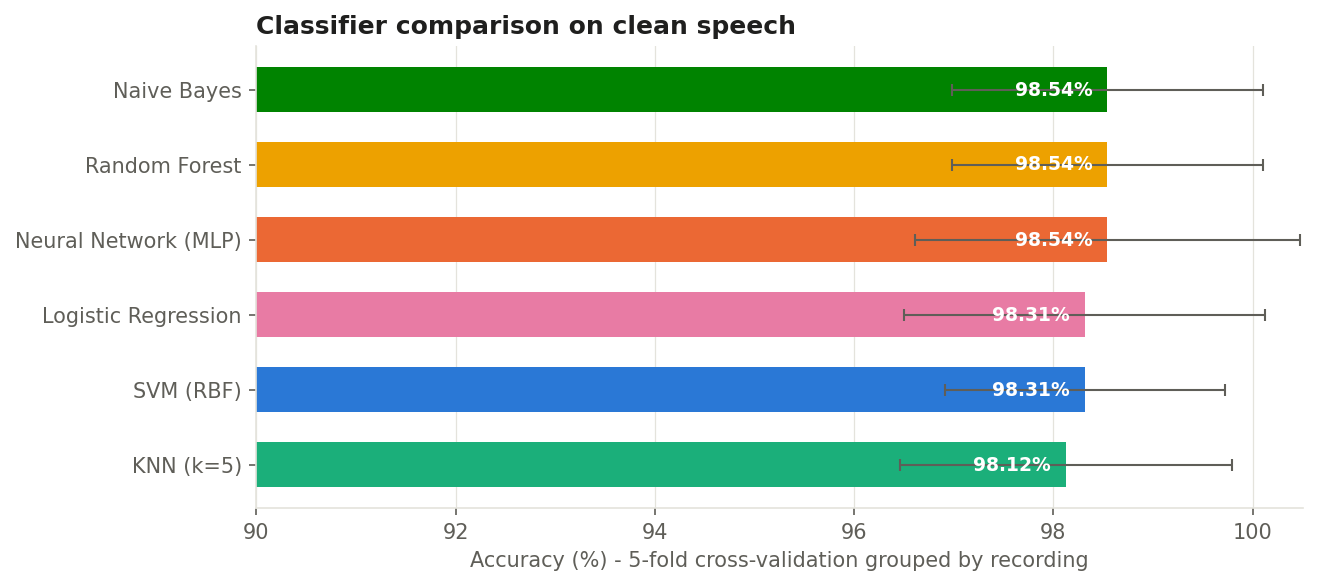

**fig06_confusion_matrices_5dB**

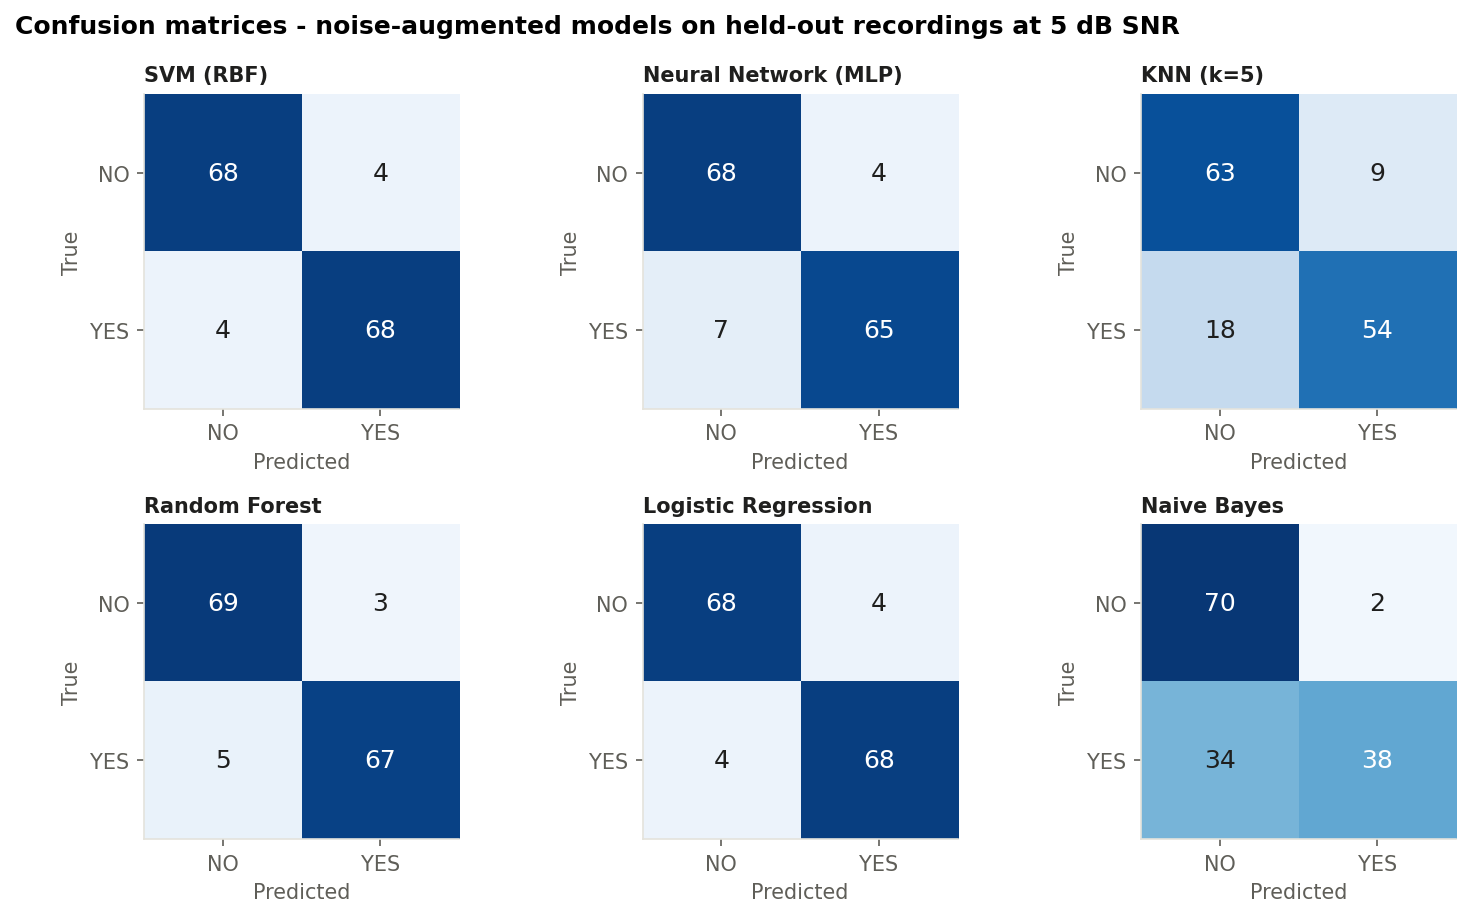

**fig07_noise_robustness**

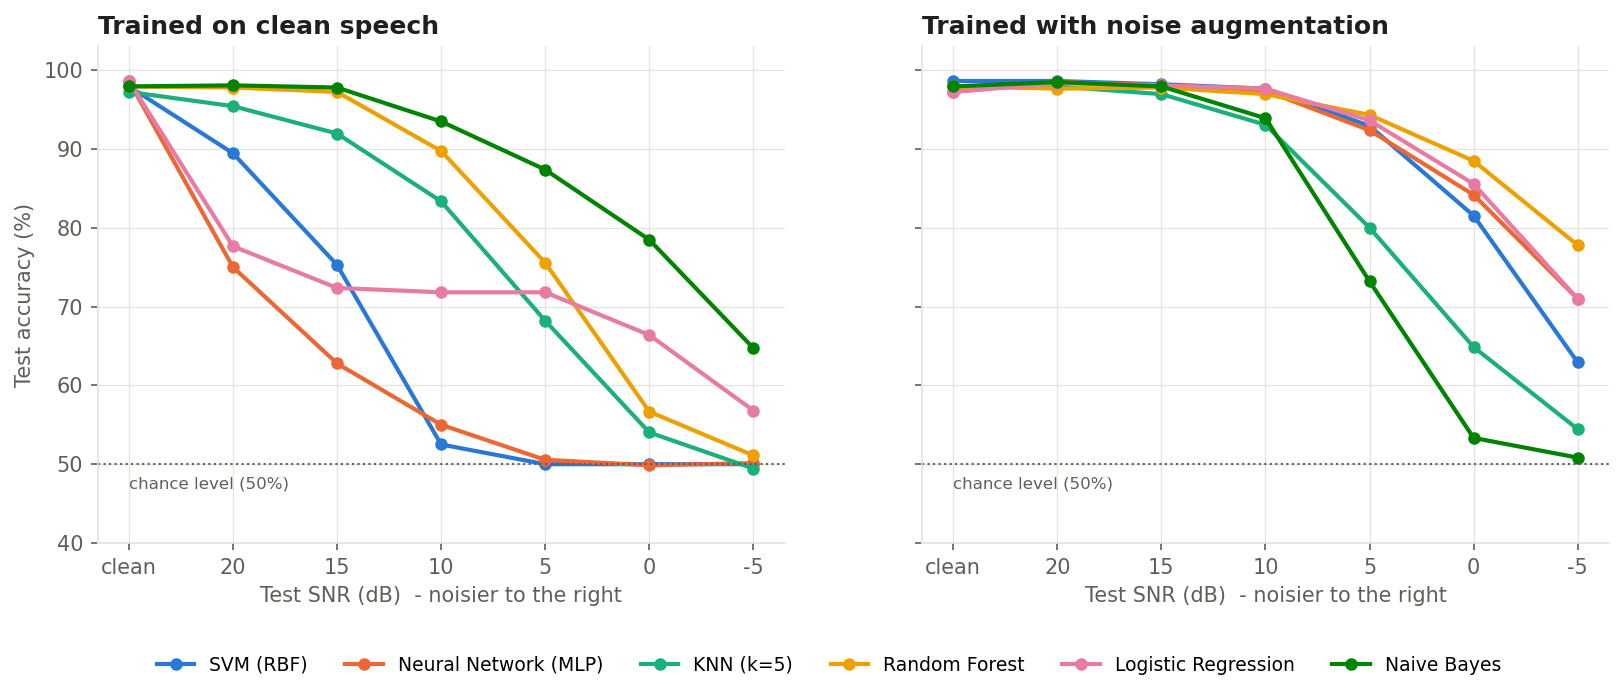

In [19]:
from pathlib import Path
from IPython.display import Image, display, Markdown
for f in sorted(Path('figures').glob('*.png')):
    display(Markdown(f'**{f.stem}**'))
    display(Image(filename=str(f)))

## 4. Results table

In [20]:
import json, pandas as pd
r = json.load(open('results/results.json'))
cv = pd.DataFrame(r['cv']).T[['acc_mean','acc_std','f1_mean','fit_ms']].astype(float)
cv[['acc_mean','acc_std','f1_mean']] *= 100
display(cv.round(2).rename(columns={'acc_mean':'Accuracy %','acc_std':'± std','f1_mean':'Macro-F1 %','fit_ms':'Train ms'}))
for mode in ['clean_train','multi_train']:
    df = pd.DataFrame(r['noise'][mode], index=r['snr_levels']).T * 100
    display(Markdown(f'**Noise test — {mode}** (accuracy %, columns = SNR dB)'))
    display(df.round(1))

,Accuracy %,± std,Macro-F1 %,Train ms
SVM (RBF),98.31,1.41,98.31,11.49
Neural Network (MLP),98.54,1.93,98.54,561.75
KNN (k=5),98.12,1.67,98.12,4.07
Random Forest,98.54,1.56,98.54,995.19
Logistic Regression,98.31,1.81,98.31,11.65
Naive Bayes,98.54,1.56,98.54,4.28


**Noise test — clean_train** (accuracy %, columns = SNR dB)

,clean,20,15,10,5,0,-5
SVM (RBF),97.9,89.4,75.3,52.5,50.0,50.0,50.0
Neural Network (MLP),98.6,75.0,62.8,55.0,50.6,49.9,50.1
KNN (k=5),97.2,95.4,91.9,83.3,68.2,54.0,49.4
Random Forest,97.9,97.8,97.2,89.7,75.6,56.7,51.1
Logistic Regression,98.6,77.6,72.4,71.8,71.8,66.4,56.8
Naive Bayes,97.9,98.1,97.8,93.5,87.4,78.5,64.7


**Noise test — multi_train** (accuracy %, columns = SNR dB)

,clean,20,15,10,5,0,-5
SVM (RBF),98.6,98.6,98.2,97.6,92.9,81.5,62.9
Neural Network (MLP),97.2,98.5,98.1,97.4,92.4,84.2,71.0
KNN (k=5),97.9,97.9,96.9,93.1,80.0,64.9,54.4
Random Forest,97.9,97.6,97.8,96.9,94.3,88.5,77.8
Logistic Regression,97.2,98.3,98.1,97.6,93.6,85.6,71.0
Naive Bayes,97.9,98.5,97.9,93.9,73.2,53.3,50.8


## 5. Full report

In [21]:
display(Markdown(Path('README.md').read_text(encoding='utf-8')))

# Mini-Task 8 — Part 1: Spoken "Yes" / "No" Classification

**Course:** Digital Speech Processing — Dr. Khalooei
**Student:** Ghassan Alsafar — **ID:** 404131085

---

## 1. Goal

Classify isolated spoken words as **YES** or **NO**, compare several classifiers
(including **SVM** and a **Neural Network**), and report the results. Because
all models are close to perfect on clean audio, a **noise-robustness study** was
added to show which models really generalise, and the whole pipeline was also
run on **recordings of my own voice** (Part B, section 6).

## 2. Dataset — OpenSLR `yesno`

| Property | Value |
|---|---|
| Source | OpenSLR resource 1 (`waves_yesno.tar.gz`) |
| Recordings | 60 `.wav` files, one speaker |
| Words per recording | 8 (Hebrew *ken* = YES, *lo* = NO) |
| Sample rate | 8000 Hz, mono |
| Average duration | 6.13 s per recording |
| Labels | in the file name, e.g. `0_1_1_0_...wav` → NO, YES, YES, NO, … |
| Class balance | 249 YES / 223 NO words |

![Signal and spectrogram](figures/fig01_signal_and_spectrogram.png)

The waveform shows eight clear bursts of energy separated by silence; the
spectrogram shows that each word has its own formant pattern, which is what
the MFCC features capture.

## 3. Method

```
 .wav ─► energy-based word segmentation ─► 8 words ─► MFCC + ΔMFCC (52-dim) ─► classifier ─► YES / NO
```

### 3.1 Word segmentation (energy-based VAD)

1. Short-time energy in dB (25 ms frames, 10 ms hop), lightly smoothed.
2. Adaptive threshold between the noise floor (10th percentile) and the speech
   peak (99th percentile); several levels are tried and the one that yields
   exactly 8 words is kept.
3. Gaps shorter than 150 ms are merged, blobs shorter than 100 ms are dropped,
   30 ms of padding is added before each word and a 150 ms **hangover** after it
   (never past the middle of the pause), so weak word endings such as the /s/
   of English "yes" are not cut off.

**Result:** exactly 8 words were found in **59 of 60**
recordings. Recordings with a different count were excluded so that every word keeps its correct label: `0_1_0_1_0_0_0_0`.
Total words used: **472**.

![Energy segmentation](figures/fig02_energy_segmentation.png)

### 3.2 Features — MFCC implemented from scratch

Pre-emphasis (0.97) → 25 ms Hamming frames → 512-point FFT → 26 Mel filters →
log → DCT → first 13 coefficients. Each word is summarised by the **mean and
standard deviation of the 13 MFCCs and of their deltas → 52 features**.

![Yes vs No](figures/fig03_yes_vs_no.png)

![PCA](figures/fig04_feature_space_pca.png)

Even in two PCA dimensions the two classes form two clearly separated clusters,
so high accuracy is expected.

### 3.3 Classifiers

| Model | Settings |
|---|---|
| SVM | RBF kernel, C = 10, standardised features |
| Neural Network (MLP) | 2 hidden layers (64, 32), ReLU, Adam, L2 = 1e-3 |
| KNN | k = 5, standardised features |
| Random Forest | 200 trees |
| Logistic Regression | L2, standardised features |
| Naive Bayes | Gaussian |

### 3.4 Evaluation protocol

* **Grouped 5-fold cross-validation by recording** — all 8 words of a recording
  are always in the same fold, so the test set never contains words from a
  recording seen during training.
* A fixed **70 / 30 split by recording** (41 train /
  18 test recordings) is used for the noise study.
* **Noise study:** white Gaussian noise is added to the test words at
  SNR = 20, 15, 10, 5, 0, −5 dB (average of 5 random noise draws).
  Two training conditions are compared: *clean only* and *multi-condition*
  (each training word is also added once with noise at a random SNR between
  0 and 20 dB).

## 4. Results

### 4.1 Clean speech — 5-fold grouped cross-validation

| Model | Accuracy (%) | Macro-F1 (%) | Training time (ms) |
|---|---:|---:|---:|
| SVM (RBF) | 98.31 ± 1.41 | 98.31 | 11.5 |
| Neural Network (MLP) | 98.54 ± 1.93 | 98.54 | 561.8 |
| KNN (k=5) | 98.12 ± 1.67 | 98.12 | 4.1 |
| Random Forest | 98.54 ± 1.56 | 98.54 | 995.2 |
| Logistic Regression | 98.31 ± 1.81 | 98.31 | 11.7 |
| Naive Bayes | 98.54 ± 1.56 | 98.54 | 4.3 |

![Model comparison](figures/fig05_model_comparison.png)

Best on clean speech: **Neural Network (MLP)**, **Random Forest**, **Naive Bayes** (tied) — 98.54%.

### 4.2 Noise robustness — test accuracy (%)

**Trained on clean speech**

| Model | clean | 20 dB | 15 dB | 10 dB | 5 dB | 0 dB | -5 dB |
|---|---:|---:|---:|---:|---:|---:|---:|
| SVM (RBF) | 97.9 | 89.4 | 75.3 | 52.5 | 50.0 | 50.0 | 50.0 |
| Neural Network (MLP) | 98.6 | 75.0 | 62.8 | 55.0 | 50.6 | 49.9 | 50.1 |
| KNN (k=5) | 97.2 | 95.4 | 91.9 | 83.3 | 68.2 | 54.0 | 49.4 |
| Random Forest | 97.9 | 97.8 | 97.2 | 89.7 | 75.6 | 56.7 | 51.1 |
| Logistic Regression | 98.6 | 77.6 | 72.4 | 71.8 | 71.8 | 66.4 | 56.8 |
| Naive Bayes | 97.9 | 98.1 | 97.8 | 93.5 | 87.4 | 78.5 | 64.7 |

**Trained with noise augmentation (multi-condition)**

| Model | clean | 20 dB | 15 dB | 10 dB | 5 dB | 0 dB | -5 dB |
|---|---:|---:|---:|---:|---:|---:|---:|
| SVM (RBF) | 98.6 | 98.6 | 98.2 | 97.6 | 92.9 | 81.5 | 62.9 |
| Neural Network (MLP) | 97.2 | 98.5 | 98.1 | 97.4 | 92.4 | 84.2 | 71.0 |
| KNN (k=5) | 97.9 | 97.9 | 96.9 | 93.1 | 80.0 | 64.9 | 54.4 |
| Random Forest | 97.9 | 97.6 | 97.8 | 96.9 | 94.3 | 88.5 | 77.8 |
| Logistic Regression | 97.2 | 98.3 | 98.1 | 97.6 | 93.6 | 85.6 | 71.0 |
| Naive Bayes | 97.9 | 98.5 | 97.9 | 93.9 | 73.2 | 53.3 | 50.8 |

![Noise robustness](figures/fig07_noise_robustness.png)

Confusion matrices of the noise-augmented models on the held-out recordings at 5 dB SNR:

![Confusion matrices](figures/fig06_confusion_matrices_5dB.png)

## 5. Discussion

1. **The clean task is easy.** Two words from one speaker in a quiet room are
   well separated by MFCCs (see the PCA plot), so most classifiers reach
   (almost) 100 %. Clean accuracy alone therefore cannot rank the models.
2. **Noise separates the models.** Averaged over all noise levels (20 → −5 dB)
   with clean training, **Naive Bayes** is the most robust
   (86.6% mean accuracy) and **Neural Network (MLP)** degrades the most
   (57.2%). Noise fills the silent parts and the high
   frequencies of each word, which shifts the MFCC statistics away from what a
   clean-trained model has seen.
3. **Noise augmentation helps a lot.** Adding noisy copies of the training words
   raises the mean noisy-test accuracy by **+15.8 points** on average over
   all models; the most robust model in that setting is **Random Forest**
   (92.2% mean, 88.5% at 0 dB).
4. **SVM vs Neural Network.** Both are at the top on clean speech; under noise,
   SVM reaches 81.5% and the MLP 84.2%
   at 0 dB (multi-condition training). With only 472 training words the
   small MLP has little data to learn from; a larger, multi-speaker dataset would
   be needed for a neural network to show a clear advantage over the SVM.

**Limitations.** One speaker and only two words; white noise only; word
boundaries for the noise study come from the clean signal. Next steps: more
speakers (e.g. Google Speech Commands), real background noise (babble, music)
and spectrogram-based CNNs.

## 7. How to run

```bash
pip install -r requirements.txt
python yesno_classification.py
```

The script downloads the data (~4.5 MB), then writes every figure to
`figures/`, every number to `results/results.json`, and regenerates this README.
Run time: about one minute on a laptop.

## 8. Files

```
MiniTask08_YesNo/
├── yesno_classification.py   # the whole pipeline
├── requirements.txt
├── README.md                 # this report (auto-generated)
├── MiniTask08_YesNo.ipynb    # notebook that runs the pipeline and shows the results
├── my_voice/                 # Part B: my own 10 recordings (80 words)
├── figures/                  # all figures
└── results/results.json      # all numbers
```

*Environment: Python 3.13.9, scikit-learn 1.7.2,
NumPy 2.3.5.*
